### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
import matplotlib.colors as mcolors
import matplotlib.tri as tri
import torch
import gpytorch
from pyproj import Proj, transform
from matplotlib import rcParams as rc
import matplotlib
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from shapely.geometry import Polygon
import geopandas as gpd

#import user models
#from pylib_gp_twoscale import VelGPModel, Genevarikernel
from pylib_gp_twoscale import VelGPModel, Genevarikernel

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Times New Roman'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 16,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
norm = mcolors.Normalize(vmin=150., vmax=2000.)  
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

In [4]:
dir_out = '../Data/Vel_data/'
dir_model = './'
cn_x = ['vs_depth','Z_2.5','surf_elevation','easting','northing'] #output
cn_y = 'diff'   
crs_grid = []

#create x,y,z grid
points_xy = [(-117.2917, 34.0935)]
points_z = np.linspace(0, 50, 51)

for x, y in points_xy:
    for z in points_z:
        crs_grid.append([x, y, z])

#wite geometry for ucvm query
with open(dir_out+'Point_input/'+'ucvm_input_3.txt', "w", encoding="utf-8") as file:
    for i in crs_grid:
        file.write(" ".join(map(str, i)) + "\n") 

In [5]:
df_ucvm = pd.read_csv(dir_out+'Point_input/'+'ucvm_output_3.txt', sep=r'\s+', 
                      header=None,
                      names=['long','lat','vs_depth','site_elevation','vs30',
                             'cvm','cvm_vp','cvm_vs','cvm_dens',
                             'gtl','gtl_vp','gtl_vs','gtl_dens',
                             'alg','vp','vs','dens'])

# get the UTM coordinate
def longlat_to_utm(lon, lat):
    utm_zone = int((lon + 180) / 6) + 1
    proj = Proj(proj='utm', zone=utm_zone, ellps='WGS84')
    easting, northing = proj(lon, lat)
    return easting, northing

df_ucvm[['easting', 'northing']] = df_ucvm.apply(lambda row: pd.Series(longlat_to_utm(row['long'], row['lat'])), axis=1)

df_ucvm['distance'] = np.linalg.norm((df_ucvm[['easting','northing']] - df_ucvm.loc[0,['easting','northing']]).values.astype(float), 
                                     axis=1)
df_ucvm['Z_2.5'] = 1820
df_ucvm = df_ucvm.rename(columns={'site_elevation': 'surf_elevation'})
df_ucvm['basin_idnum'] = 4
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,gtl_dens,alg,vp,vs,dens,easting,northing,distance,Z_2.5,basin_idnum
0,-117.2917,34.0935,0.0,305.389,296.381,cvms5,1615.518,893.166,2052.700,none,...,0.0,crust,1615.518,893.166,2052.700,473091.644005,3.772562e+06,0.0,1820,4
1,-117.2917,34.0935,1.0,305.389,296.381,cvms5,1616.472,893.633,2052.934,none,...,0.0,crust,1616.472,893.633,2052.934,473091.644005,3.772562e+06,0.0,1820,4
2,-117.2917,34.0935,2.0,305.389,296.381,cvms5,1617.427,894.100,2053.168,none,...,0.0,crust,1617.427,894.100,2053.168,473091.644005,3.772562e+06,0.0,1820,4
3,-117.2917,34.0935,3.0,305.389,296.381,cvms5,1618.381,894.567,2053.401,none,...,0.0,crust,1618.381,894.567,2053.401,473091.644005,3.772562e+06,0.0,1820,4
4,-117.2917,34.0935,4.0,305.389,296.381,cvms5,1619.336,895.034,2053.635,none,...,0.0,crust,1619.336,895.034,2053.635,473091.644005,3.772562e+06,0.0,1820,4
5,-117.2917,34.0935,5.0,305.389,296.381,cvms5,1620.290,895.501,2053.868,none,...,0.0,crust,1620.290,895.501,2053.868,473091.644005,3.772562e+06,0.0,1820,4
6,-117.2917,34.0935,6.0,305.389,296.381,cvms5,1621.245,895.968,2054.102,none,...,0.0,crust,1621.245,895.968,2054.102,473091.644005,3.772562e+06,0.0,1820,4
7,-117.2917,34.0935,7.0,305.389,296.381,cvms5,1622.199,896.435,2054.335,none,...,0.0,crust,1622.199,896.435,2054.335,473091.644005,3.772562e+06,0.0,1820,4
8,-117.2917,34.0935,8.0,305.389,296.381,cvms5,1623.154,896.902,2054.568,none,...,0.0,crust,1623.154,896.902,2054.568,473091.644005,3.772562e+06,0.0,1820,4
9,-117.2917,34.0935,9.0,305.389,296.381,cvms5,1624.108,897.370,2054.801,none,...,0.0,crust,1624.108,897.370,2054.801,473091.644005,3.772562e+06,0.0,1820,4


In [6]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
0,610,1.00,155.0,0.5,1.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,938.187,251.052,2380.0,-1.800524,2
1,610,2.00,170.2,1.5,2.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.068,251.052,2380.0,-1.707914,2
2,610,3.00,196.5,2.5,3.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.949,251.052,2380.0,-1.565163,2
3,610,4.00,191.9,3.5,4.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,940.830,251.052,2380.0,-1.589788,2
4,610,5.00,202.0,4.5,5.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,941.711,251.052,2380.0,-1.539431,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,2479,12.60,354.0,9.3,15.9,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,894.882,54.938,3620.0,-0.927395,1
11027,2479,21.15,387.0,15.9,26.4,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,899.010,54.938,3620.0,-0.842869,1
11028,2479,34.80,445.0,26.4,43.2,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,905.600,54.938,3620.0,-0.710523,1
11029,2479,56.60,540.0,43.2,70.0,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,916.125,54.938,3620.0,-0.528584,1


In [7]:
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1


In [8]:
df_sonic = pd.read_csv(dir_out+'Training_data/df_sonic.txt', encoding='utf-8')
df_sonic = df_sonic.rename(columns={'X': 'easting', 'Y': 'northing',
                                       'depth': 'vs_depth'})
df_sonic = df_sonic[['vs_depth','Z_2.5','surf_elevation','easting','northing','diff',  'velocity_metadata_id']]

df_sonic['basin_idnum'] = 1
df_sonic

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,basin_idnum
0,67.124000,4400.0,23.596,387402.0000,3753149.500,0.010634,-29,1
1,77.124000,4400.0,23.596,387402.0000,3753149.500,0.018006,-29,1
2,87.124000,4400.0,23.596,387402.0000,3753149.500,0.028627,-29,1
3,97.124000,4400.0,23.596,387402.0000,3753149.500,0.040313,-29,1
4,107.124000,4400.0,23.596,387402.0000,3753149.500,0.051009,-29,1
...,...,...,...,...,...,...,...,...
3177,1956.730197,2500.0,83.353,387298.0938,3767711.984,-0.116894,-28,1
3178,1966.730197,2500.0,83.353,387298.0938,3767711.984,-0.056673,-28,1
3179,1976.730197,2500.0,83.353,387298.0938,3767711.984,-0.040450,-28,1
3180,1986.730197,2500.0,83.353,387298.0938,3767711.984,-0.050204,-28,1


In [9]:
df_veldata = pd.concat([df_measure.reset_index(drop=True), df_sonic.reset_index(drop=True)], ignore_index=True, sort=False)
df_veldata

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
14208,1956.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.116894,-28,NaN,1
14209,1966.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.056673,-28,NaN,1
14210,1976.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.040450,-28,NaN,1
14211,1986.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.050204,-28,NaN,1


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#read model
scaler_input = load(open(dir_model+'ucvm_la_basin_adj_scaler_frozen.pkl', 'rb'))
model_state = torch.load(dir_model+'ucvm_la_basin_adj_model_frozen_newloss.pth', weights_only=True)

#get training input/output
X_train = scaler_input.transform(df_veldata.loc[:,cn_x].values)
Y_train = df_veldata.loc[:,cn_y].values
#convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float64)
Y_train = torch.tensor(Y_train, dtype=torch.float64)

basin_col = torch.tensor(
    df_veldata['basin_idnum'].to_numpy(),
    dtype=X_train.dtype,
    device=X_train.device
).unsqueeze(1)

X_train = torch.cat([X_train, basin_col], dim=1)
print(X_train)

#define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device).double()
model = VelGPModel(X_train, Y_train, likelihood).to(device).double()
model.load_state_dict(model_state)

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [30.8894, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.0499, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000],
        [31.2105, -0.1001, -0.6438,  0.1647, -0.1566,  1.0000]],
       dtype=torch.float64)


<All keys matched successfully>

In [12]:
X_train_cross = torch.tensor(scaler_input.transform(df_ucvm.loc[:,cn_x].values), dtype=torch.float64)
Y_train_cross = df_ucvm['cvm_vs'].values
Y_train_cross

basin_col = torch.tensor(
    df_ucvm['basin_idnum'].to_numpy(),
    dtype=X_train_cross.dtype,
    device=X_train_cross.device
).unsqueeze(1)

X_train_cross = torch.cat([X_train_cross, basin_col], dim=1)
print(X_train_cross)


X_train_cross.max(axis=0)
X_train.max(axis=0)


df_veldata.loc[:,cn_x].values.max(axis=0)
df_veldata.loc[df_veldata.vs_depth > 380,:].velocity_metadata_id.unique()

tensor([[-0.8418, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.8257, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.8097, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.7936, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.7776, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.7615, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.7455, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.7294, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.7134, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.6973, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.6813, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.6652, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.6492, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.6331, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.6171, -0.5835,  0.5237,  3.1397,  0.0115,  4.0000],
        [-0.6010, -0.5835,  0.5237,  3.1

array([-29, -30, -31, -32, -33,  -1,  -2,  -3,  -4,  -5,  -6,  -7,  -8,
        -9, -10, -11, -12, -13, -14, -15, -16, -17, -18, -19, -22, -23,
       -24, -25, -26, -27, -28])

In [13]:
#train GP model
model.eval()
likelihood.eval()

with torch.no_grad():
    observed_pred = likelihood(model(X_train_cross.to(device).double()))
    predict_value = observed_pred.mean.detach().cpu()
    std = observed_pred.stddev.detach().cpu()

    #samples = model(X_train_cross.to(device).double()).rsample(torch.Size([3]))
    #fstd = model(X_train_cross.to(device).double()).stddev



lower = predict_value - 1.96 * std
upper = predict_value + 1.96 * std

In [14]:
df_ucvm['predict_diff'] = predict_value
#df_ucvm['predict_vs'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff"].to_numpy()*df_ucvm['factor'])
df_ucvm['predict_vs'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff"].to_numpy())

df_ucvm['predict_diff_low'] = lower
df_ucvm['predict_vs_low'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff_low"].to_numpy())
df_ucvm['predict_diff_upper'] = upper
df_ucvm['predict_vs_upper'] = df_ucvm["cvm_vs"].to_numpy() * np.exp(df_ucvm["predict_diff_upper"].to_numpy())

In [15]:
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,northing,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,predict_diff_low,predict_vs_low,predict_diff_upper,predict_vs_upper
0,-117.2917,34.0935,0.0,305.389,296.381,cvms5,1615.518,893.166,2052.700,none,...,3.772562e+06,0.0,1820,4,-1.493627,200.566422,-2.110589,108.221896,-0.876665,371.707493
1,-117.2917,34.0935,1.0,305.389,296.381,cvms5,1616.472,893.633,2052.934,none,...,3.772562e+06,0.0,1820,4,-1.448484,209.937707,-2.065077,113.320246,-0.831891,388.931745
2,-117.2917,34.0935,2.0,305.389,296.381,cvms5,1617.427,894.100,2053.168,none,...,3.772562e+06,0.0,1820,4,-1.403209,219.776040,-2.019540,118.661784,-0.786877,407.051925
3,-117.2917,34.0935,3.0,305.389,296.381,cvms5,1618.381,894.567,2053.401,none,...,3.772562e+06,0.0,1820,4,-1.358019,230.055562,-1.974223,124.227785,-0.741815,426.036427
4,-117.2917,34.0935,4.0,305.389,296.381,cvms5,1619.336,895.034,2053.635,none,...,3.772562e+06,0.0,1820,4,-1.313126,240.744327,-1.929262,130.008439,-0.696990,445.800530
5,-117.2917,34.0935,5.0,305.389,296.381,cvms5,1620.290,895.501,2053.868,none,...,3.772562e+06,0.0,1820,4,-1.268731,251.804238,-1.884837,135.985223,-0.652626,466.266646
6,-117.2917,34.0935,6.0,305.389,296.381,cvms5,1621.245,895.968,2054.102,none,...,3.772562e+06,0.0,1820,4,-1.225024,263.191165,-1.841115,142.136761,-0.608933,487.344648
7,-117.2917,34.0935,7.0,305.389,296.381,cvms5,1622.199,896.435,2054.335,none,...,3.772562e+06,0.0,1820,4,-1.182181,274.855248,-1.798273,148.435867,-0.566090,508.943081
8,-117.2917,34.0935,8.0,305.389,296.381,cvms5,1623.154,896.902,2054.568,none,...,3.772562e+06,0.0,1820,4,-1.140366,286.741385,-1.756413,154.861905,-0.524319,530.928648
9,-117.2917,34.0935,9.0,305.389,296.381,cvms5,1624.108,897.370,2054.801,none,...,3.772562e+06,0.0,1820,4,-1.099726,298.790253,-1.715780,161.368152,-0.483673,553.241853


In [16]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum','vs_value']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing', 'diff_smooth': 'diff'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_value
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2,155.0
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2,170.2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2,196.5
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2,191.9
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2,202.0
...,...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1,354.0
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1,387.0
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1,445.0
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1,540.0


In [17]:
def get_vs0(vs30 = 293.5):
    p1 = -2.1688e-4
    p2 = 0.5182
    p3 = 69.452
    return p1 * vs30**2 + p2 * vs30 + p3

def get_k(vs30 = 293.5):
    r1 = -59.67
    r2 = -0.2722
    r3 = 11.132
    return np.exp(r1 * (vs30**r2) + r3)

def get_n(vs30 = 293.5):
    s1 = 4.110
    s2 = -1.0521e-4
    s3 = -10.827
    s4 = -7.6187e-3
    return s1 * np.exp(s2 * vs30) + s3 * np.exp(s4 * vs30)

def get_vs_z(z, vs30):
    z = np.asarray(z)
    vs0 = get_vs0(vs30)
    k = get_k(vs30)
    n = get_n(vs30)
    vs = np.where(
        z <= 2.5,
        vs0,
        vs0 * (1.0 + k * (z - 2.5))**(1.0 / n)
    )
    return vs

vs = get_vs_z(df_ucvm['vs_depth'], 293.5)
df_ucvm['shi'] = vs
df_ucvm

,long,lat,vs_depth,surf_elevation,vs30,cvm,cvm_vp,cvm_vs,cvm_dens,gtl,...,distance,Z_2.5,basin_idnum,predict_diff,predict_vs,predict_diff_low,predict_vs_low,predict_diff_upper,predict_vs_upper,shi
0,-117.2917,34.0935,0.0,305.389,296.381,cvms5,1615.518,893.166,2052.700,none,...,0.0,1820,4,-1.493627,200.566422,-2.110589,108.221896,-0.876665,371.707493,202.861169
1,-117.2917,34.0935,1.0,305.389,296.381,cvms5,1616.472,893.633,2052.934,none,...,0.0,1820,4,-1.448484,209.937707,-2.065077,113.320246,-0.831891,388.931745,202.861169
2,-117.2917,34.0935,2.0,305.389,296.381,cvms5,1617.427,894.100,2053.168,none,...,0.0,1820,4,-1.403209,219.776040,-2.019540,118.661784,-0.786877,407.051925,202.861169
3,-117.2917,34.0935,3.0,305.389,296.381,cvms5,1618.381,894.567,2053.401,none,...,0.0,1820,4,-1.358019,230.055562,-1.974223,124.227785,-0.741815,426.036427,210.044828
4,-117.2917,34.0935,4.0,305.389,296.381,cvms5,1619.336,895.034,2053.635,none,...,0.0,1820,4,-1.313126,240.744327,-1.929262,130.008439,-0.696990,445.800530,223.201180
5,-117.2917,34.0935,5.0,305.389,296.381,cvms5,1620.290,895.501,2053.868,none,...,0.0,1820,4,-1.268731,251.804238,-1.884837,135.985223,-0.652626,466.266646,235.074621
6,-117.2917,34.0935,6.0,305.389,296.381,cvms5,1621.245,895.968,2054.102,none,...,0.0,1820,4,-1.225024,263.191165,-1.841115,142.136761,-0.608933,487.344648,245.942559
7,-117.2917,34.0935,7.0,305.389,296.381,cvms5,1622.199,896.435,2054.335,none,...,0.0,1820,4,-1.182181,274.855248,-1.798273,148.435867,-0.566090,508.943081,255.997047
8,-117.2917,34.0935,8.0,305.389,296.381,cvms5,1623.154,896.902,2054.568,none,...,0.0,1820,4,-1.140366,286.741385,-1.756413,154.861905,-0.524319,530.928648,265.377241
9,-117.2917,34.0935,9.0,305.389,296.381,cvms5,1624.108,897.370,2054.801,none,...,0.0,1820,4,-1.099726,298.790253,-1.715780,161.368152,-0.483673,553.241853,274.187598


In [18]:
from pyproj import Transformer

target_lat = 34.0935
target_lon = -117.2917

transformer = Transformer.from_crs("EPSG:4326", "EPSG:32611", always_xy=True)
target_easting, target_northing = transformer.transform(target_lon, target_lat)

dist = np.sqrt(
    (df_measure["easting"].to_numpy() - target_easting)**2 +
    (df_measure["northing"].to_numpy() - target_northing)**2
)

df_measure["dist_m"] = dist

row_nearest = df_measure.loc[df_measure["dist_m"].idxmin()]
row_nearest

vs_depth                1.150000e+00
Z_2.5                   1.660000e+03
surf_elevation          3.077810e+02
easting                 4.735077e+05
northing                3.772882e+06
diff                   -1.627129e+00
velocity_metadata_id    1.422000e+03
vs30                    3.191440e+02
basin_idnum             4.000000e+00
vs_value                1.770000e+02
dist_m                  5.250809e+02
Name: 9691, dtype: float64

In [19]:
df_close = df_measure[df_measure['velocity_metadata_id'] == 1422]
df_close

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum,vs_value,dist_m
9691,1.15,1660.0,307.781,473507.658903,3.772882e+06,-1.627129,1422,319.144,4,177.0,525.080906
9692,4.00,1660.0,307.781,473507.658903,3.772882e+06,-1.457674,1422,319.144,4,210.0,525.080906
9693,7.20,1660.0,307.781,473507.658903,3.772882e+06,-1.010410,1422,319.144,4,329.0,525.080906
9694,9.95,1660.0,307.781,473507.658903,3.772882e+06,-1.228184,1422,319.144,4,265.0,525.080906
9695,11.70,1660.0,307.781,473507.658903,3.772882e+06,-0.866035,1422,319.144,4,381.0,525.080906
9696,14.60,1660.0,307.781,473507.658903,3.772882e+06,-0.975544,1422,319.144,4,342.0,525.080906
9697,20.10,1660.0,307.781,473507.658903,3.772882e+06,-0.897033,1422,319.144,4,371.0,525.080906
9698,26.05,1660.0,307.781,473507.658903,3.772882e+06,-0.402881,1422,319.144,4,610.0,525.080906
9699,29.70,1660.0,307.781,473507.658903,3.772882e+06,-1.081668,1422,319.144,4,310.0,525.080906
9700,32.60,1660.0,307.781,473507.658903,3.772882e+06,-0.575581,1422,319.144,4,515.0,525.080906


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

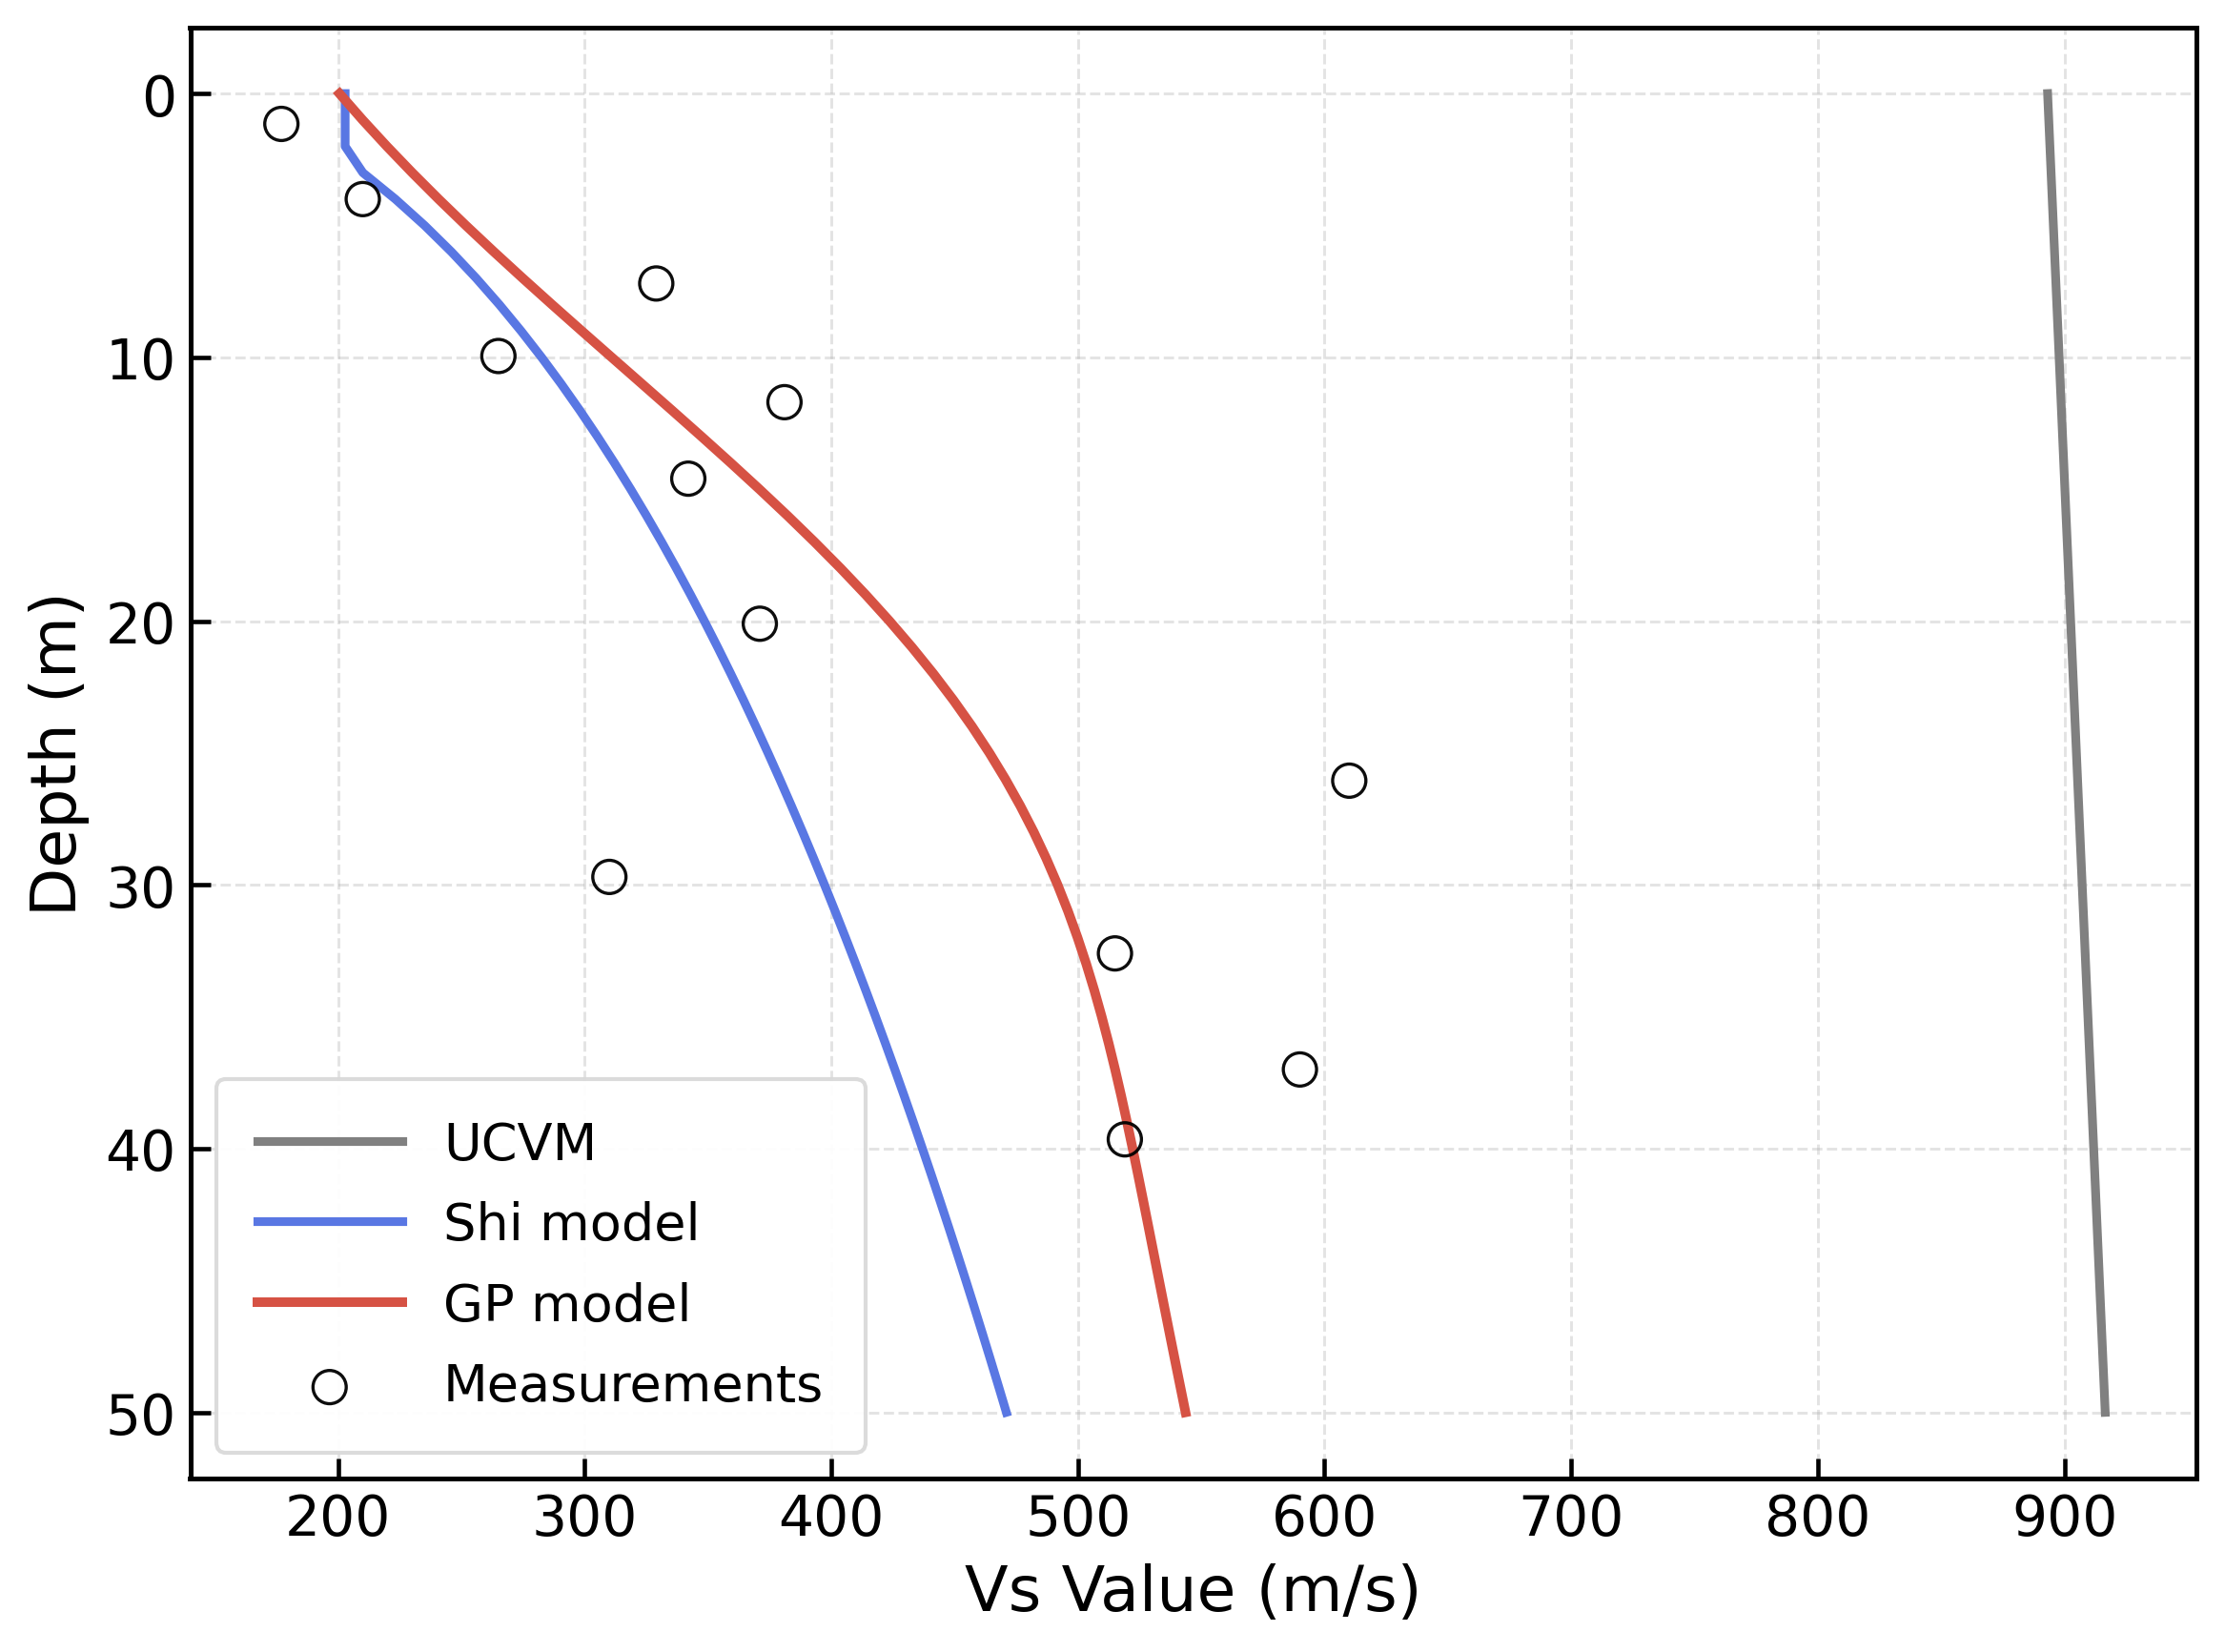

In [20]:
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)


plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 14
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)


ax.plot(
    df_ucvm['cvm_vs'], df_ucvm['vs_depth'],
    color='gray', lw=2.2, label="UCVM"
)

ax.plot(
    df_ucvm['shi'], df_ucvm['vs_depth'],
    color=blue_color, lw=2.2, label="Shi model"
)

ax.plot(
    df_ucvm['predict_vs'], df_ucvm['vs_depth'],
    color=red_color, lw=2.4, label="GP model"
)

ax.scatter(
    df_close['vs_value'], df_close['vs_depth'],
    s=70, color="black",
    linewidth=0.8, alpha=0.95, label="Measurements",
    facecolors="none",
    edgecolors="black",
    zorder=5
)

ax.invert_yaxis()
ax.set_xlabel("Vs Value (m/s)", fontsize=16)
ax.set_ylabel("Depth (m)", fontsize=16)

ax.grid(
    True, which="major",
    linestyle="--", linewidth=0.7, alpha=0.35
)


ax.tick_params(axis="both", which="major", labelsize=14, length=5, width=1.1)

leg = ax.legend(
    loc="lower left",
    fontsize=13,
    frameon=True,
    handlelength=2.8,
    borderpad=0.8,
    labelspacing=0.6
)
leg.get_frame().set_edgecolor("0.85")
leg.get_frame().set_linewidth(1.0)
leg.get_frame().set_alpha(0.95)

plt.tight_layout()
plt.show()

In [21]:
df_ucvm.to_csv(dir_out+'Point_input/'+'df_ucvm_3.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')